# Exploratory Data Analysis on a Cars Dataset
**Student:** Garvit Singh  |  **Batch:** October  |  **Date:** 19 October 2026

**Dataset:** `cardata.csv`

## 0. Imports and settings

In [59]:
import os, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [60]:
# Load the raw dataset
import pandas as pd

try:
    raw = pd.read_csv('cardata.csv')
    print(f"Successfully loaded cardata.csv! Shape: {raw.shape}")
    display(raw.head())

    # Define shape variables required later in cell c10
    rows_before, cols_before = raw.shape
except FileNotFoundError:
    print("Error: 'cardata.csv' not found. Please verify the filename and upload path.")

Successfully loaded cardata.csv! Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### Column mapping
The code looks for the common car columns by name. **Check the printed mapping.** If a column is wrong or missing,
set it manually in `COLUMN_OVERRIDES`, e.g. `{"price": "selling_price"}`, and re-run.

In [61]:
# Load standard column names and map them manually to make the code simple
COLUMN_OVERRIDES = {
    "Selling_Price": "price",
    "Year": "year",
    "Car_Name": "brand",
    "Fuel_Type": "fuel",
    "Kms_Driven": "mileage",
    "Transmission": "transmission"
}

df = raw.rename(columns=COLUMN_OVERRIDES)
BRAND_LABEL = "Car Name"

## 2. Data quality checks

In [62]:
print("=== 2. DATA QUALITY CHECKS ===")

# 1. Print percentage of missing values in each column
print("Missing values (%):")
for col_name in df.columns:
    number_of_nulls = df[col_name].isna().sum()
    total_rows = len(df)
    percentage_missing = (number_of_nulls / total_rows) * 100
    print(f"{col_name}: {percentage_missing:.2f}%")

# 2. Count duplicate rows
number_of_duplicates = df.duplicated().sum()
print(f"\nDuplicate rows: {number_of_duplicates}")

# 3. Check categories for Fuel and Transmission
if "fuel" in df.columns:
    unique_fuels = sorted(df["fuel"].dropna().unique())
    print(f"\nLabels in 'fuel': {unique_fuels}")

if "transmission" in df.columns:
    unique_transmissions = sorted(df["transmission"].dropna().unique())
    print(f"Labels in 'transmission': {unique_transmissions}")

# 4. Check for impossible values
price_series = pd.to_numeric(df["price"], errors="coerce")
impossible_prices = (price_series <= 0).sum()
print(f"\nPrice <= 0: {impossible_prices}")

if "mileage" in df.columns:
    mileage_series = pd.to_numeric(df["mileage"], errors="coerce")
    impossible_mileage = (mileage_series < 0).sum()
    print(f"Mileage < 0: {impossible_mileage}")

=== 2. DATA QUALITY CHECKS ===
Missing values (%):
brand: 0.00%
year: 0.00%
price: 0.00%
Present_Price: 0.00%
mileage: 0.00%
fuel: 0.00%
Seller_Type: 0.00%
transmission: 0.00%
Owner: 0.00%

Duplicate rows: 2

Labels in 'fuel': ['CNG', 'Diesel', 'Petrol']
Labels in 'transmission': ['Automatic', 'Manual']

Price <= 0: 0
Mileage < 0: 0


## 3. Data cleaning

In [63]:
# 3.1 Remove duplicate rows
clean = df.drop_duplicates().copy()
dups_removed = len(df) - len(clean)

# 3.2 Drop rows that are missing core values
n0 = len(clean)
clean = clean.dropna(subset=["price", "year", "mileage"])

# 3.3 Remove impossible values
this_year = 2026
clean = clean[clean["price"] > 0]
clean = clean[(clean["year"] >= 1980) & (clean["year"] <= this_year)]
if "mileage" in clean.columns:
    clean = clean[clean["mileage"] >= 0]

# 3.4 Add vehicle age column
clean["year"] = clean["year"].astype(int)
REF_YEAR = int(clean["year"].max())
clean["age"] = REF_YEAR - clean["year"]

print("=== 3. CLEANING RESULT ===")
print(f"Duplicates removed: {dups_removed}")
print(f"Final shape: {clean.shape}")

=== 3. CLEANING RESULT ===
Duplicates removed: 2
Final shape: (299, 10)


## 4. Descriptive statistics

In [64]:
print("=== 4. DESCRIPTIVE STATISTICS ===")

# 1. Print summary for numerical columns
print("\nNumerical columns summary:")
display(clean.describe().round(2))

# 2. Print summary for categorical columns
print("\nCategorical columns summary:")
display(clean.describe(exclude=[np.number]))

=== 4. DESCRIPTIVE STATISTICS ===

Numerical columns summary:


,year,price,Present_Price,mileage,Owner,age
count,299.00,299.00,299.00,299.00,299.00,299.00
mean,2013.62,4.59,7.54,36916.75,0.04,4.38
std,2.90,4.98,8.57,39015.17,0.25,2.90
min,2003.00,0.10,0.32,500.00,0.00,0.00
25%,2012.00,0.85,1.20,15000.00,0.00,2.00
50%,2014.00,3.51,6.10,32000.00,0.00,4.00
75%,2016.00,6.00,9.84,48883.50,0.00,6.00
max,2018.00,35.00,92.60,500000.00,3.00,15.00



Categorical columns summary:


,brand,fuel,Seller_Type,transmission
count,299,299,299,299
unique,98,3,2,2
top,city,Petrol,Dealer,Manual
freq,26,239,193,260


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 5. Visual EDA

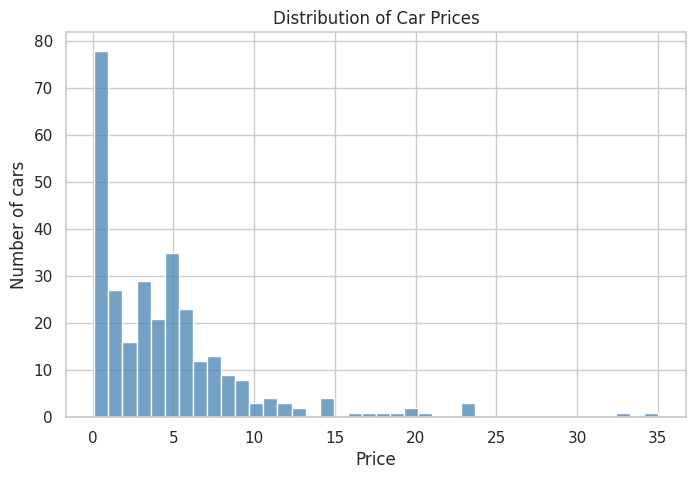

In [65]:
# Chart 1 - Distribution of Car Prices
plt.figure(figsize=(8, 5))
sns.histplot(clean["price"], bins=40, color="steelblue")
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.show()

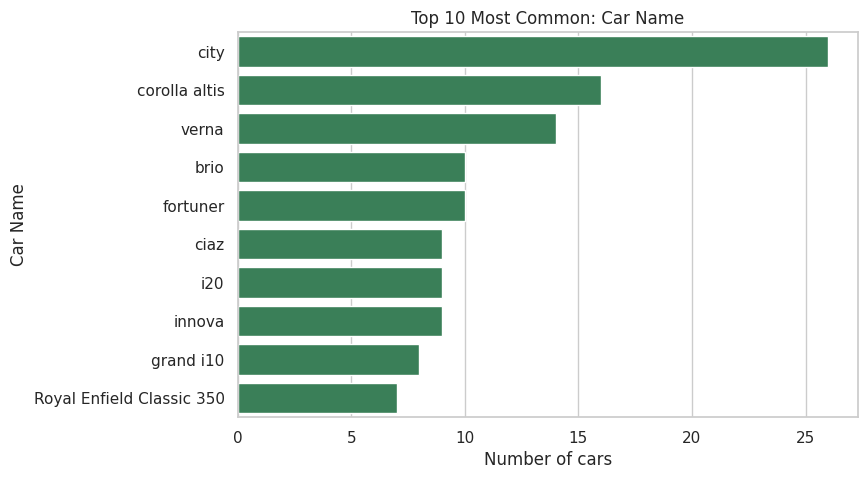

In [66]:
# Chart 2 - Top 10 Most Common Car Names
if "brand" in clean.columns:
    top = clean["brand"].value_counts().head(10)
    plt.figure(figsize=(8, 5))
    sns.barplot(x=top.values, y=top.index, color="seagreen")
    plt.title("Top 10 Most Common: Car Name")
    plt.xlabel("Number of cars")
    plt.ylabel("Car Name")
    plt.show()

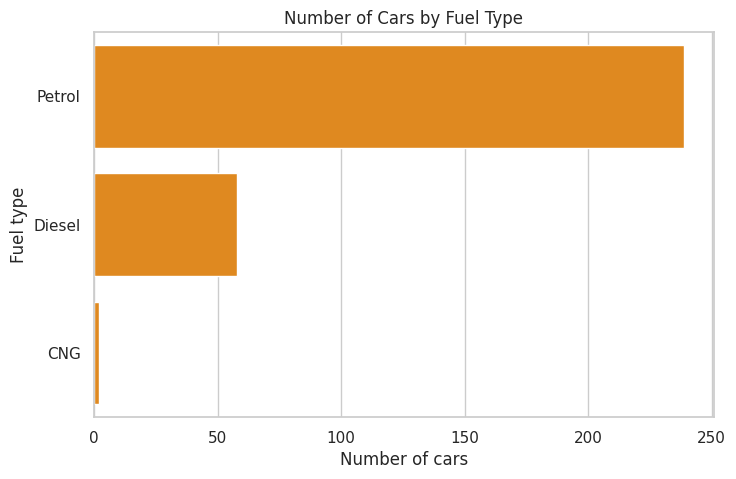

In [67]:
# Chart 3 - Number of Cars by Fuel Type
if "fuel" in clean.columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=clean, y="fuel", order=clean["fuel"].value_counts().index, color="darkorange")
    plt.title("Number of Cars by Fuel Type")
    plt.xlabel("Number of cars")
    plt.ylabel("Fuel type")
    plt.show()

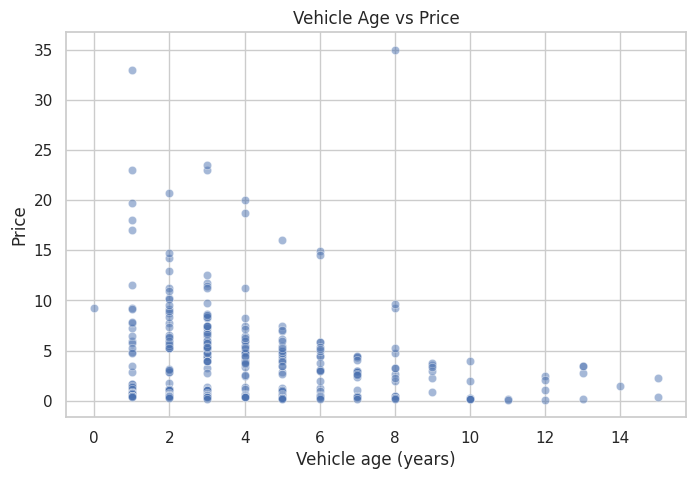

In [68]:
# Chart 4 - Vehicle Age vs Price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=clean, x="age", y="price", alpha=0.5)
plt.title("Vehicle Age vs Price")
plt.xlabel("Vehicle age (years)")
plt.ylabel("Price")
plt.show()

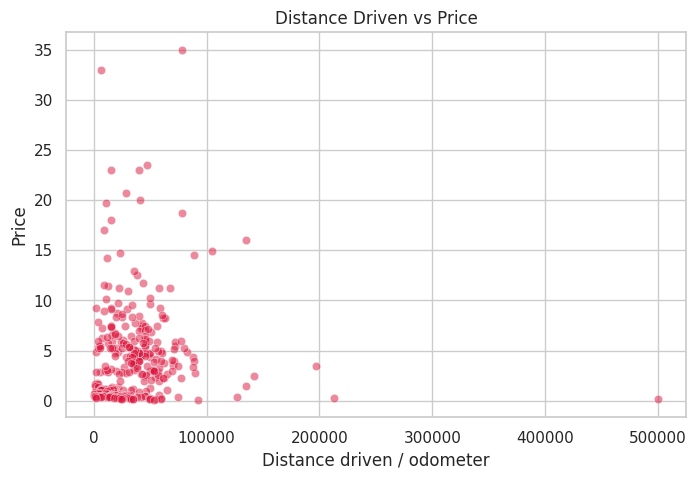

In [69]:
# Chart 5 - Distance Driven vs Price
if "mileage" in clean.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=clean, x="mileage", y="price", alpha=0.5, color="crimson")
    plt.title("Distance Driven vs Price")
    plt.xlabel("Distance driven / odometer")
    plt.ylabel("Price")
    plt.show()

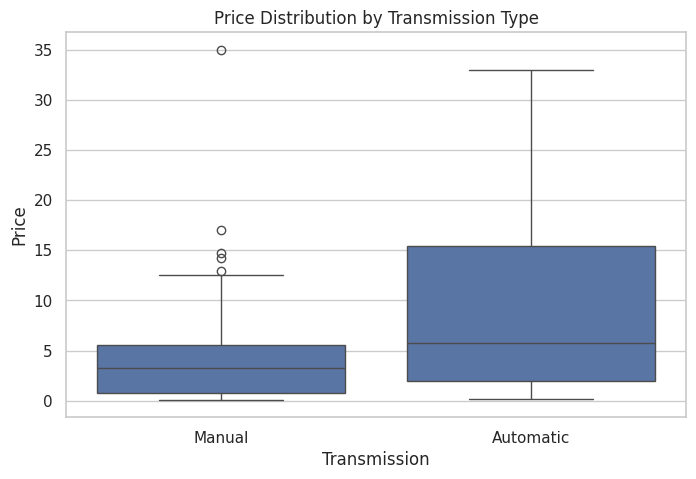

In [70]:
# Chart 6 - Price Distribution by Transmission Type
if "transmission" in clean.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=clean, x="transmission", y="price")
    plt.title("Price Distribution by Transmission Type")
    plt.xlabel("Transmission")
    plt.ylabel("Price")
    plt.show()

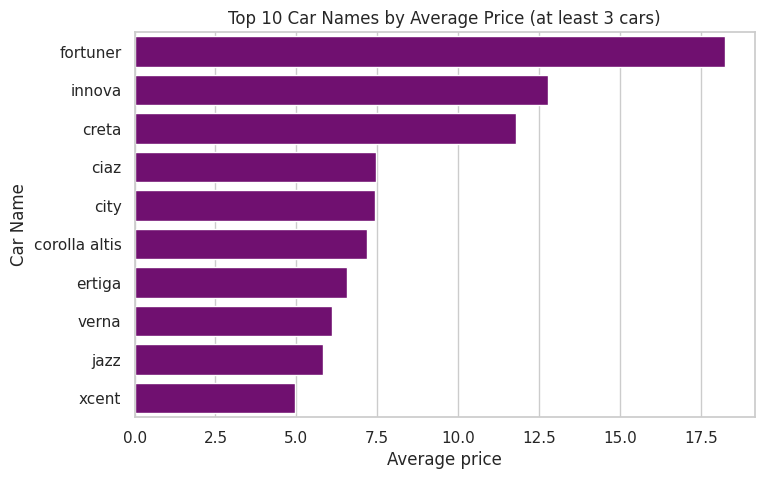

In [71]:
# Chart 7 - Top 10 Brands by Average Price
if "brand" in clean.columns:
    min_n = 3
    stats = clean.groupby("brand")["price"].agg(["mean", "count"])
    top_avg = stats[stats["count"] >= min_n].sort_values("mean", ascending=False).head(10)
    plt.figure(figsize=(8, 5))
    sns.barplot(x=top_avg["mean"], y=top_avg.index, color="purple")
    plt.title(f"Top 10 Car Names by Average Price (at least {min_n} cars)")
    plt.xlabel("Average price")
    plt.ylabel("Car Name")
    plt.show()

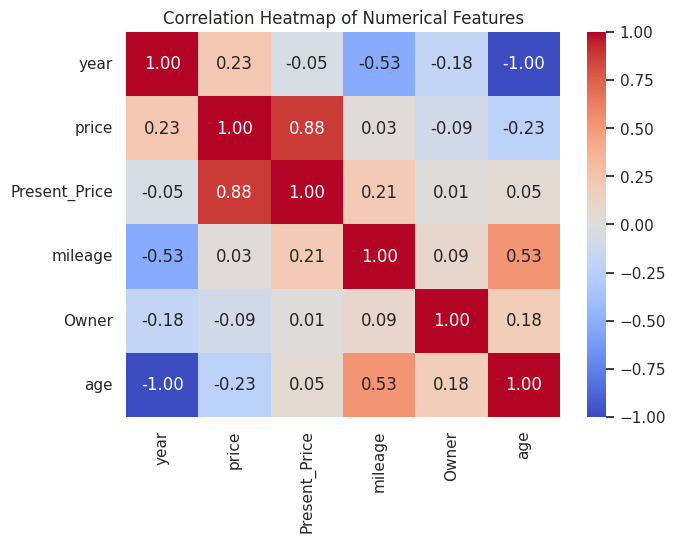

In [72]:
# Chart 8 - Correlation Heatmap of Numerical Features
num_cols = clean.select_dtypes(include="number").columns.tolist()
corr = clean[num_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

## 6. Evidence for key findings
Use these numbers for your five findings. Only claim what the numbers support; correlation is not causation.

In [73]:
print("=== 5. KEY FINDING EVIDENCE ===")

# 1. Simple median and mean calculation
median_price = clean["price"].median()
mean_price = clean["price"].mean()
print(f"Median price: {median_price:.2f} | Mean price: {mean_price:.2f}")

# 2. Simple top brands percentage calculation
if "brand" in clean.columns:
    print(f"\nTop 5 most common Car Name (% of cars):")
    brand_counts = clean["brand"].value_counts()
    total_cars = len(clean)

    for brand_name in brand_counts.head(5).index:
        count = brand_counts[brand_name]
        percentage = (count / total_cars) * 100
        print(f"{brand_name:<16s} {percentage:.1f}")

# 3. Simple fuel type shares
if "fuel" in clean.columns:
    print("\nFuel type share (%):")
    fuel_counts = clean["fuel"].value_counts()
    for fuel_name in fuel_counts.index:
        count = fuel_counts[fuel_name]
        percentage = (count / total_cars) * 100
        print(f"{fuel_name:<16s} {percentage:.1f}")

# 4. Simple median price by transmission
if "transmission" in clean.columns:
    print("\nMedian price by transmission:")
    for trans_type in clean["transmission"].unique():
        subset = clean[clean["transmission"] == trans_type]
        median_val = subset["price"].median()
        print(f"{trans_type:<16s} {median_val:.2f}")

# 5. Simple median price by age group
print("\nMedian price by age group:")
for low, high in [(0, 2), (2, 4), (4, 6), (6, 15)]:
    subset = clean[(clean["age"] >= low) & (clean["age"] <= high)]
    if len(subset) > 0:
        median_val = subset["price"].median()
        print(f"({float(low)}, {float(high)}]    {median_val:.2f}")

# 6. Simple correlation list
print("\nCorrelation of every numerical feature with price:")
numeric_cols = clean.select_dtypes(include=np.number).columns
for col_name in numeric_cols:
    correlation_value = clean[col_name].corr(clean["price"])
    print(f"{col_name:<16s} {correlation_value:.2f}")

=== 5. KEY FINDING EVIDENCE ===
Median price: 3.51 | Mean price: 4.59

Top 5 most common Car Name (% of cars):
city             8.7
corolla altis    5.4
verna            4.7
brio             3.3
fortuner         3.3

Fuel type share (%):
Petrol           79.9
Diesel           19.4
CNG              0.7

Median price by transmission:
Manual           3.25
Automatic        5.75

Median price by age group:
(0.0, 2.0]    4.80
(2.0, 4.0]    4.75
(4.0, 6.0]    3.90
(6.0, 15.0]    2.55

Correlation of every numerical feature with price:
year             0.23
price            1.00
Present_Price    0.88
mileage          0.03
Owner            -0.09
age              -0.23
